In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import load_model

# Dataset paths
APTOS_DIR = Path(
    "/kaggle/input/datasets/mjayanth007/aptos-preprocessed/aptos_preprocessed"
)

IDRID_DIR = Path(
    "/kaggle/input/datasets/mjayanth007/idrid-dataset/idrid_preprocessed"
)

# Fine-tuned ResNet50 checkpoint
MODEL_PATH = Path(
    "/kaggle/input/models/mjayanth007/resnet/keras/default/1/"
    "resnet_outputs/resnet50_finetuned_best.keras"
)

# Model configuration
IMAGE_SIZE = (224, 224)
CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

for name, path in {
    "APTOS dataset": APTOS_DIR,
    "IDRiD dataset": IDRID_DIR,
    "Fine-tuned ResNet50 model": MODEL_PATH
}.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    print(f"  {path}")

TensorFlow: 2.20.0
GPU available: False
APTOS dataset: FOUND
  /kaggle/input/datasets/mjayanth007/aptos-preprocessed/aptos_preprocessed


2026-10-22 12:37:16.997533: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


IDRiD dataset: FOUND
  /kaggle/input/datasets/mjayanth007/idrid-dataset/idrid_preprocessed
Fine-tuned ResNet50 model: FOUND
  /kaggle/input/models/mjayanth007/resnet/keras/default/1/resnet_outputs/resnet50_finetuned_best.keras


In [2]:
# Load the fine-tuned ResNet50 model
model = load_model(MODEL_PATH, compile=False)

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nModel layers:")
for i, layer in enumerate(model.layers):
    print(
        f"{i:3d} | {layer.name:40s} | "
        f"{layer.__class__.__name__:25s} | "
        f"Output shape: {layer.output.shape}"
    )

Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)

Model layers:
  0 | input_layer_1                            | InputLayer                | Output shape: (None, 224, 224, 3)
  1 | resnet50                                 | Functional                | Output shape: (None, 7, 7, 2048)
  2 | global_average_pooling2d                 | GlobalAveragePooling2D    | Output shape: (None, 2048)
  3 | dropout                                  | Dropout                   | Output shape: (None, 2048)
  4 | dense                                    | Dense                     | Output shape: (None, 5)


In [3]:
# Access the nested ResNet50 backbone
backbone = model.get_layer("resnet50")

print("Backbone output shape:", backbone.output.shape)
print("\nLast 20 backbone layers:\n")

for layer in backbone.layers[-20:]:
    print(
        f"{layer.name:40s} "
        f"{layer.__class__.__name__:25s} "
        f"{layer.output.shape}"
    )

Backbone output shape: (None, 7, 7, 2048)

Last 20 backbone layers:

conv5_block2_1_conv                      Conv2D                    (None, 7, 7, 512)
conv5_block2_1_bn                        BatchNormalization        (None, 7, 7, 512)
conv5_block2_1_relu                      Activation                (None, 7, 7, 512)
conv5_block2_2_conv                      Conv2D                    (None, 7, 7, 512)
conv5_block2_2_bn                        BatchNormalization        (None, 7, 7, 512)
conv5_block2_2_relu                      Activation                (None, 7, 7, 512)
conv5_block2_3_conv                      Conv2D                    (None, 7, 7, 2048)
conv5_block2_3_bn                        BatchNormalization        (None, 7, 7, 2048)
conv5_block2_add                         Add                       (None, 7, 7, 2048)
conv5_block2_out                         Activation                (None, 7, 7, 2048)
conv5_block3_1_conv                      Conv2D                    (None, 7, 

In [4]:
def make_gradcam_heatmap(img_array, model, backbone, class_index=None):
    """Generate Grad-CAM for a raw RGB image batch with pixel values in [0, 255].

    ResNet50 was trained using tf.keras.applications.resnet50.preprocess_input,
    so apply that same preprocessing here before inference and gradient calculation.
    """
    # Final convolutional activation in the ResNet50 backbone
    last_conv_layer = backbone.get_layer("conv5_block3_out")

    # Produce final convolutional features and the backbone output
    feature_model = tf.keras.Model(
        inputs=backbone.inputs,
        outputs=[last_conv_layer.output, backbone.output]
    )

    # Match the ResNet50 training pipeline (RGB pixels in [0, 255])
    img_tensor = tf.cast(img_array, tf.float32)
    img_tensor = tf.keras.applications.resnet50.preprocess_input(img_tensor)

    with tf.GradientTape() as tape:
        conv_outputs, backbone_output = feature_model(
            img_tensor, training=False
        )

        # Pass backbone features through the existing trained classification head
        x = model.get_layer("global_average_pooling2d")(backbone_output)
        x = model.get_layer("dropout")(x, training=False)
        predictions = model.get_layer("dense")(x)

        predicted_class = tf.argmax(
            predictions[0], output_type=tf.int32
        )
        target_class = (
            int(predicted_class.numpy())
            if class_index is None
            else int(class_index)
        )
        class_score = predictions[:, target_class]

    grads = tape.gradient(class_score, conv_outputs)
    if grads is None:
        raise RuntimeError(
            "Gradients are None. Check that the selected convolutional layer "
            "is connected to the model output."
        )

    # Global-average the gradients to obtain channel importance weights
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    features = conv_outputs[0]
    heatmap = tf.reduce_sum(
        features * weights[tf.newaxis, tf.newaxis, :], axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), int(predicted_class.numpy()), predictions[0].numpy()

print("ResNet50 Grad-CAM function defined successfully.")

ResNet50 Grad-CAM function defined successfully.


Total images found: 455
Selected image: IDRiD_204.jpg
Original image shape: (512, 512, 3)
Model input shape: (1, 224, 224, 3)


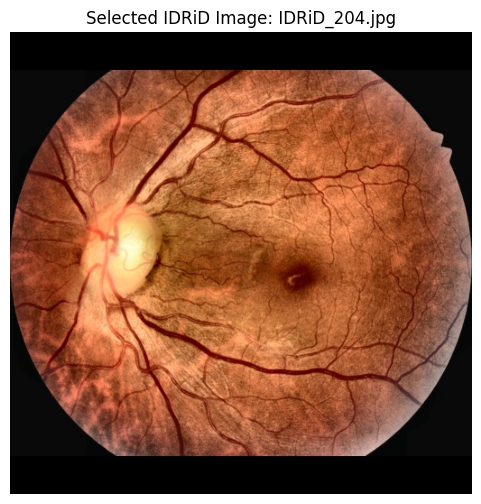

In [5]:
# Collect available images from the preprocessed IDRiD dataset
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = sorted(
    path for path in IDRID_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

print("Total images found:", len(image_paths))

assert len(image_paths) > 0, "No images found in the IDRiD dataset."

# Select the first image for the initial Grad-CAM test
IMAGE_PATH = image_paths[257]

# Load and convert BGR to RGB
image_bgr = cv2.imread(str(IMAGE_PATH))
assert image_bgr is not None, f"Could not read image: {IMAGE_PATH}"

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Prepare raw RGB image at 224x224; preprocessing is applied inside make_gradcam_heatmap
image_resized = cv2.resize(image_rgb, IMAGE_SIZE)

img_array = np.expand_dims(
    image_resized.astype(np.float32),
    axis=0
)

print("Selected image:", IMAGE_PATH.name)
print("Original image shape:", image_rgb.shape)
print("Model input shape:", img_array.shape)

plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title(f"Selected IDRiD Image: {IMAGE_PATH.name}")
plt.axis("off")
plt.show()

Predicted grade: 0
Predicted class: No DR
Model scores: [0.3792 0.1262 0.3791 0.0221 0.0934]


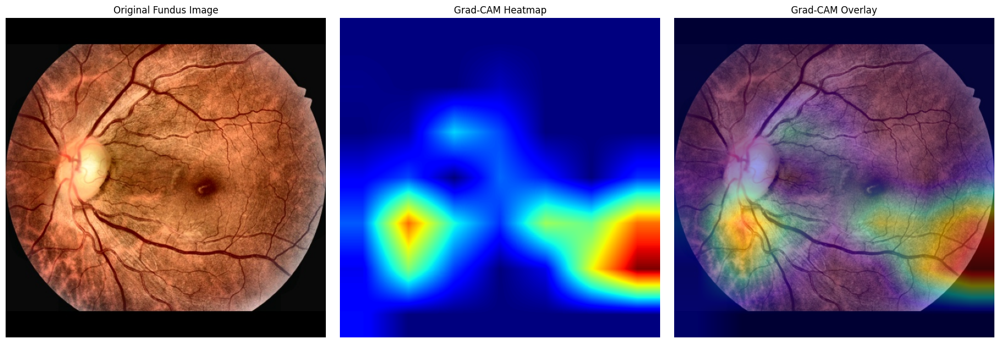

In [6]:
# Generate Grad-CAM for the model's predicted class
heatmap, predicted_class, probabilities = make_gradcam_heatmap(
    img_array=img_array,
    model=model,
    backbone=backbone
)

# Resize heatmap to match the displayed image
heatmap_resized = cv2.resize(
    heatmap,
    (image_rgb.shape[1], image_rgb.shape[0])
)

# Convert heatmap to a color map
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_color = cv2.applyColorMap(
    heatmap_uint8, cv2.COLORMAP_JET
)
heatmap_color = cv2.cvtColor(
    heatmap_color, cv2.COLOR_BGR2RGB
)

# Blend heatmap with the original fundus image
overlay = cv2.addWeighted(
    image_rgb, 0.60,
    heatmap_color, 0.40,
    0
)

print("Predicted grade:", predicted_class)
print("Predicted class:", CLASS_NAMES[predicted_class])
print("Model scores:", np.round(probabilities, 4))

# Display original, heatmap and overlay
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Fundus Image")

axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
tdf=pd.read_csv("/kaggle/input/datasets/mariaherrerot/idrid-dataset/idrid_labels.csv")

In [8]:
# Returns the entire row matching the ID
print(tdf[tdf["id_code"] == "IDRiD_204"])

# To handle minor case sensitivity or strip whitespace if needed
print(tdf[tdf["id_code"].str.strip() == "IDRiD_204"])

       id_code  diagnosis  Risk of macular edema   Unnamed: 3  Unnamed: 4  \
177  IDRiD_204          0                       0         NaN         NaN   

     Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8  Unnamed: 9  Unnamed: 10  \
177         NaN         NaN         NaN         NaN         NaN          NaN   

    Unnamed: 11  
177         NaN  
       id_code  diagnosis  Risk of macular edema   Unnamed: 3  Unnamed: 4  \
177  IDRiD_204          0                       0         NaN         NaN   

     Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8  Unnamed: 9  Unnamed: 10  \
177         NaN         NaN         NaN         NaN         NaN          NaN   

    Unnamed: 11  
177         NaN  


In [9]:
import pandas as pd

APTOS_LABELS_PATH = APTOS_DIR / "train_labels.csv"
APTOS_TRAIN_DIR = APTOS_DIR / "train"

labels_df = pd.read_csv(APTOS_LABELS_PATH)

print("Labels shape:", labels_df.shape)
print("\nColumns:", labels_df.columns.tolist())

print("\nGrade distribution:")
display(labels_df.iloc[:, -1].value_counts().sort_index())

Labels shape: (3662, 2)

Columns: ['id_code', 'diagnosis']

Grade distribution:


diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64

In [10]:
import pandas as pd
from pathlib import Path

# Index image files by filename stem
image_lookup = {
    path.stem: path
    for path in APTOS_TRAIN_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

# Match label IDs to actual image files
labels_df["image_path"] = labels_df["id_code"].map(image_lookup.get)

matched_df = labels_df.dropna(subset=["image_path"]).copy()
matched_df["diagnosis"] = matched_df["diagnosis"].astype(int)

print("Labeled images:", len(labels_df))
print("Images matched:", len(matched_df))
print("Images missing:", len(labels_df) - len(matched_df))

# Select two examples from each grade
selected_df = (
    matched_df.groupby("diagnosis", group_keys=False)
    .sample(n=2, random_state=42)
    .sort_values(["diagnosis", "id_code"])
    .reset_index(drop=True)
)

display(selected_df[["id_code", "diagnosis", "image_path"]])

Labeled images: 3662
Images matched: 3662
Images missing: 0


,id_code,diagnosis,image_path
0,0a85a1e8f9e9,0,/kaggle/input/datasets/mjayanth007/aptos-prepr...
1,ef5155990874,0,/kaggle/input/datasets/mjayanth007/aptos-prepr...
2,a19ecd0a706e,1,/kaggle/input/datasets/mjayanth007/aptos-prepr...
3,abdb365cacbc,1,/kaggle/input/datasets/mjayanth007/aptos-prepr...
4,a15590a7d774,2,/kaggle/input/datasets/mjayanth007/aptos-prepr...
5,a879c3569552,2,/kaggle/input/datasets/mjayanth007/aptos-prepr...
6,069f43616fab,3,/kaggle/input/datasets/mjayanth007/aptos-prepr...
7,aea59ebec445,3,/kaggle/input/datasets/mjayanth007/aptos-prepr...
8,612f2df37a1d,4,/kaggle/input/datasets/mjayanth007/aptos-prepr...
9,66a0bf258013,4,/kaggle/input/datasets/mjayanth007/aptos-prepr...


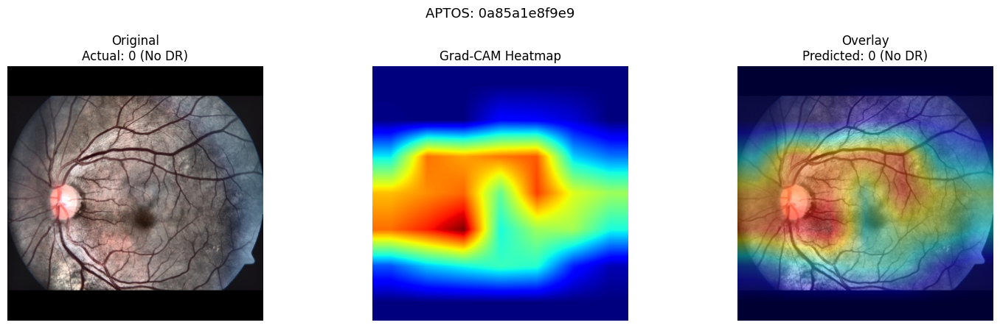

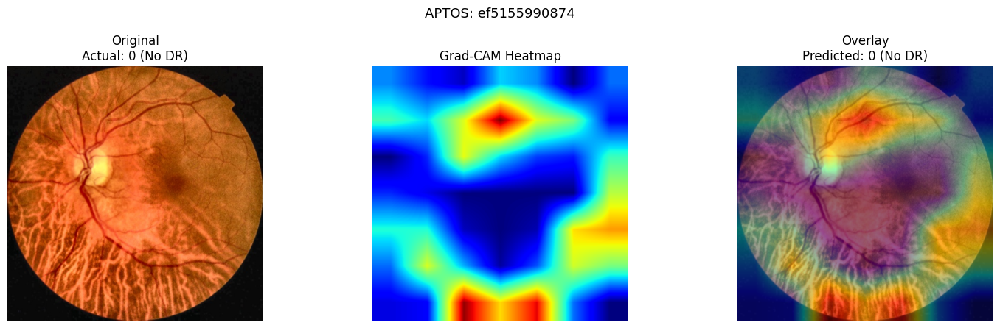

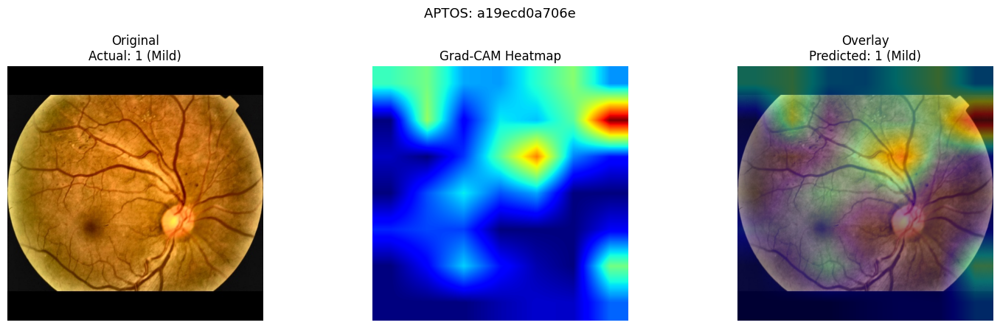

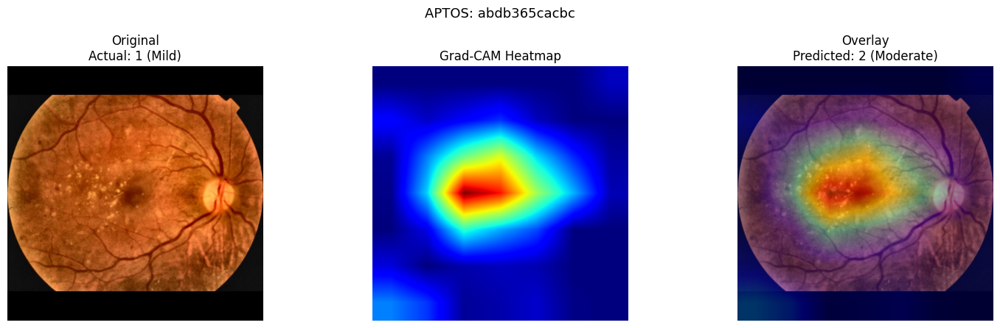

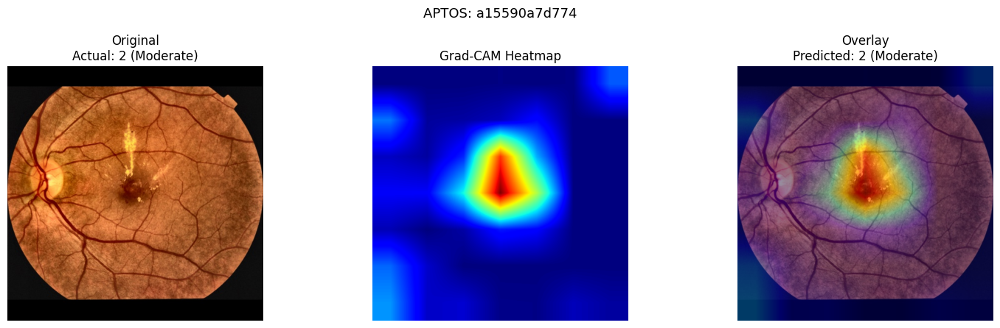

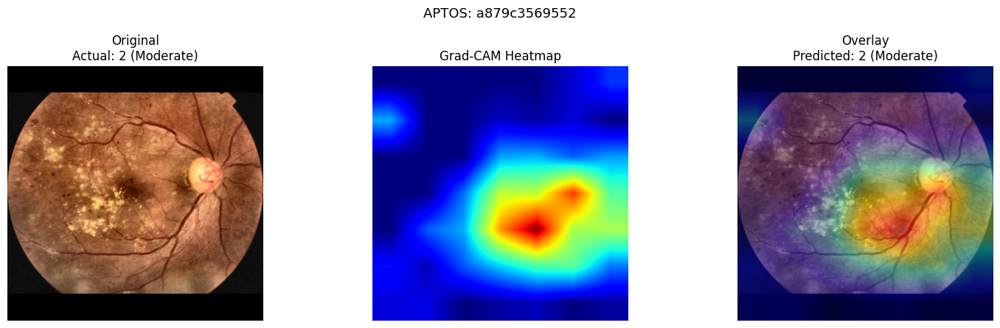

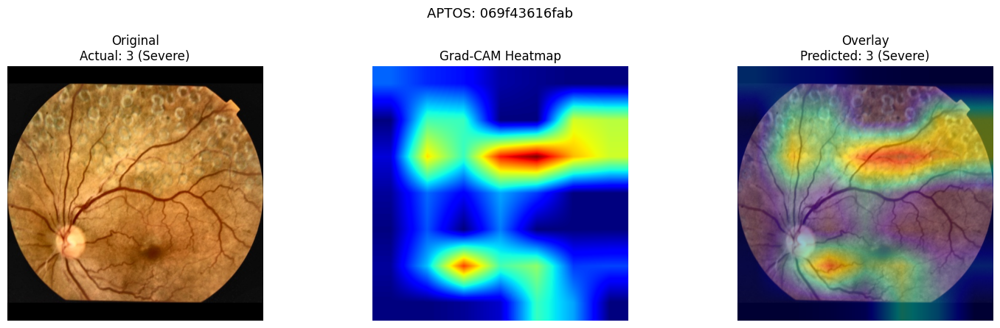

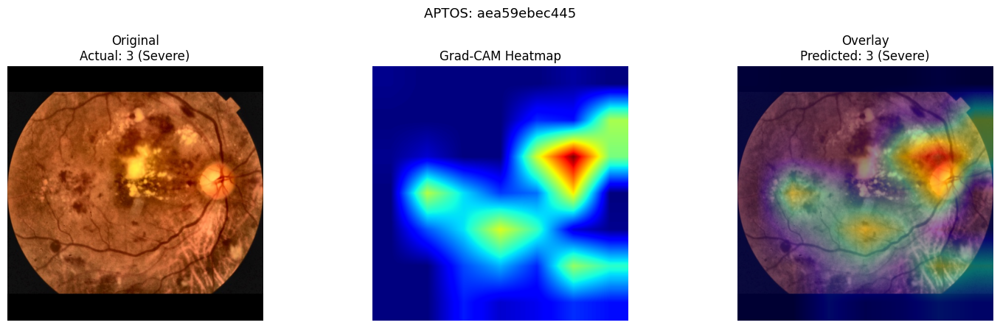

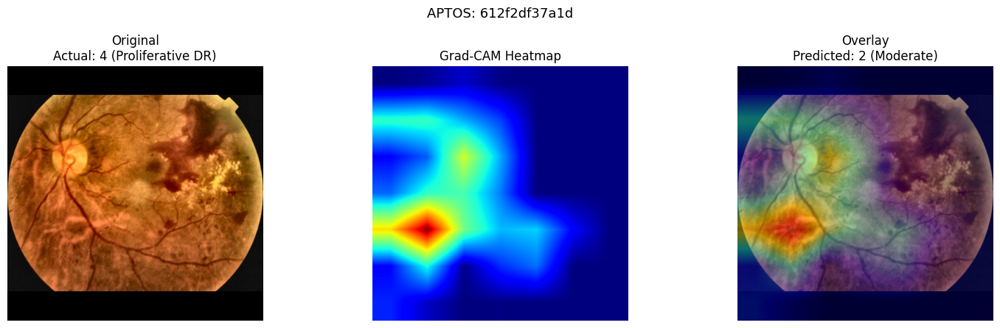

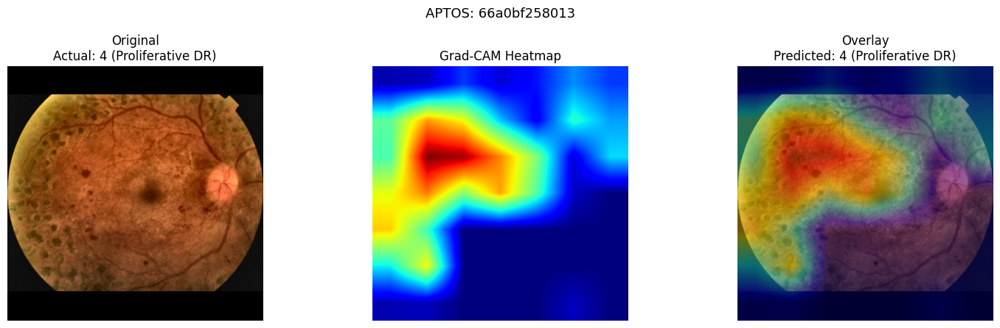

Grad-CAM examples generated: 10


,image_id,actual_grade,predicted_grade,actual_binary,predicted_binary,grade_correct,binary_correct,predicted_class_score
0,0a85a1e8f9e9,0,0,Non-Referable,Non-Referable,True,True,0.997941
1,ef5155990874,0,0,Non-Referable,Non-Referable,True,True,0.912666
2,a19ecd0a706e,1,1,Non-Referable,Non-Referable,True,True,0.643302
3,abdb365cacbc,1,2,Non-Referable,Referable,False,False,0.760338
4,a15590a7d774,2,2,Referable,Referable,True,True,0.697378
5,a879c3569552,2,2,Referable,Referable,True,True,0.779139
6,069f43616fab,3,3,Referable,Referable,True,True,0.609514
7,aea59ebec445,3,3,Referable,Referable,True,True,0.610130
8,612f2df37a1d,4,2,Referable,Referable,False,True,0.450410
9,66a0bf258013,4,4,Referable,Referable,True,True,0.922051


In [11]:
from IPython.display import display, Markdown

results = []

for _, row in selected_df.iterrows():
    image_path = Path(row["image_path"])
    actual_grade = int(row["diagnosis"])

    # Read preprocessed image
    image_bgr = cv2.imread(str(image_path))
    if image_bgr is None:
        print(f"Skipping unreadable image: {image_path.name}")
        continue

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    # Match ResNet50 input dimensions
    image_resized = cv2.resize(image_rgb, IMAGE_SIZE)
    img_array = np.expand_dims(
        image_resized.astype(np.float32), axis=0
    )

    # Generate Grad-CAM
    heatmap, predicted_grade, probabilities = make_gradcam_heatmap(
        img_array=img_array,
        model=model,
        backbone=backbone
    )

    # Resize heatmap for overlay
    heatmap_resized = cv2.resize(
        heatmap,
        (image_rgb.shape[1], image_rgb.shape[0])
    )

    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8, cv2.COLORMAP_JET
    )
    heatmap_color = cv2.cvtColor(
        heatmap_color, cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        image_rgb, 0.60, heatmap_color, 0.40, 0
    )

    # Convert five-class grades to binary categories
    actual_binary = (
        "Non-Referable" if actual_grade <= 1 else "Referable"
    )
    predicted_binary = (
        "Non-Referable" if predicted_grade <= 1 else "Referable"
    )

    results.append({
        "image_id": row["id_code"],
        "actual_grade": actual_grade,
        "predicted_grade": predicted_grade,
        "actual_binary": actual_binary,
        "predicted_binary": predicted_binary,
        "grade_correct": actual_grade == predicted_grade,
        "binary_correct": actual_binary == predicted_binary,
        "predicted_class_score": float(probabilities[predicted_grade])
    })

    # Display visualization
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    axes[0].imshow(image_rgb)
    axes[0].set_title(
        f"Original\nActual: {actual_grade} ({CLASS_NAMES[actual_grade]})"
    )

    axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM Heatmap")

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"Overlay\nPredicted: {predicted_grade} "
        f"({CLASS_NAMES[predicted_grade]})"
    )

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"APTOS: {row['id_code']}", fontsize=13)
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results)

print("Grad-CAM examples generated:", len(results_df))
display(results_df)

In [12]:
import pandas as pd
from pathlib import Path

# Original IDRiD labels
IDRID_LABELS_PATH = Path(
    "/kaggle/input/datasets/mariaherrerot/idrid-dataset/idrid_labels.csv"
)

idrid_labels_df = pd.read_csv(IDRID_LABELS_PATH)

print("Label columns:", idrid_labels_df.columns.tolist())
display(idrid_labels_df.head())

Label columns: ['id_code', 'diagnosis', 'Risk of macular edema ', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']


,id_code,diagnosis,Risk of macular edema,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,IDRiD_001,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IDRiD_004,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IDRiD_005,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# Index preprocessed IDRiD images by filename stem
idrid_image_lookup = {
    path.stem: path
    for path in IDRID_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

# Match labels to image files
idrid_labels_df["image_path"] = (
    idrid_labels_df["id_code"].astype(str).map(idrid_image_lookup.get)
)

idrid_matched_df = idrid_labels_df.dropna(
    subset=["image_path"]
).copy()

idrid_matched_df["diagnosis"] = (
    idrid_matched_df["diagnosis"].astype(int)
)

print("Labeled images:", len(idrid_labels_df))
print("Matched images:", len(idrid_matched_df))
print("Unmatched labels:", len(idrid_labels_df) - len(idrid_matched_df))

# Select two images per grade, reproducibly
idrid_selected_df = (
    idrid_matched_df.groupby("diagnosis", group_keys=False)
    .sample(n=2, random_state=42)
    .sort_values(["diagnosis", "id_code"])
    .reset_index(drop=True)
)

display(
    idrid_selected_df[["id_code", "diagnosis", "image_path"]]
)

Labeled images: 455
Matched images: 455
Unmatched labels: 0


,id_code,diagnosis,image_path
0,IDRiD_211,0,/kaggle/input/datasets/mjayanth007/idrid-datas...
1,IDRiD_228,0,/kaggle/input/datasets/mjayanth007/idrid-datas...
2,IDRiD_105,1,/kaggle/input/datasets/mjayanth007/idrid-datas...
3,IDRiD_311,1,/kaggle/input/datasets/mjayanth007/idrid-datas...
4,IDRiD_048,2,/kaggle/input/datasets/mjayanth007/idrid-datas...
5,IDRiD_103,2,/kaggle/input/datasets/mjayanth007/idrid-datas...
6,IDRiD_035,3,/kaggle/input/datasets/mjayanth007/idrid-datas...
7,IDRiD_308,3,/kaggle/input/datasets/mjayanth007/idrid-datas...
8,IDRiD_086,4,/kaggle/input/datasets/mjayanth007/idrid-datas...
9,IDRiD_324,4,/kaggle/input/datasets/mjayanth007/idrid-datas...


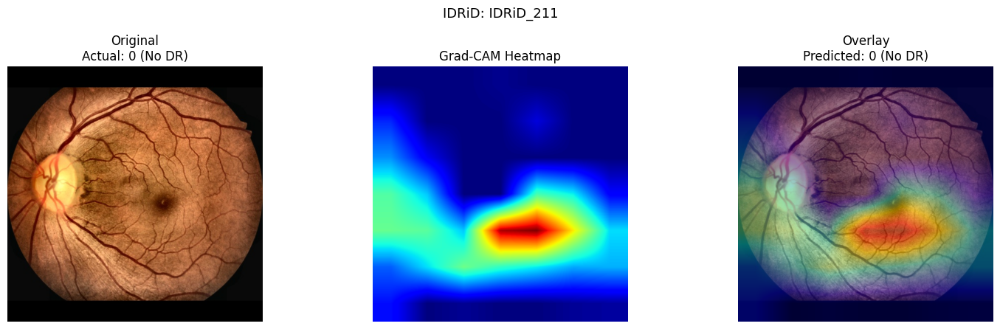

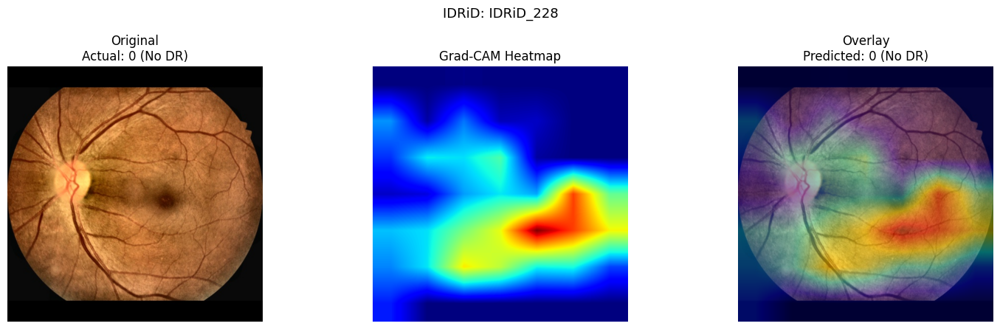

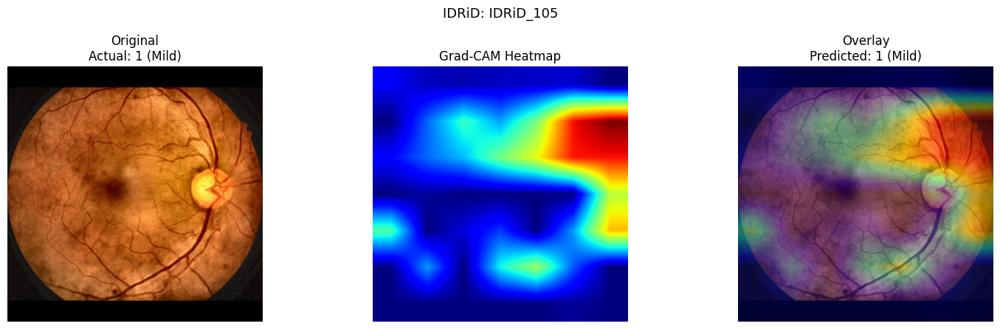

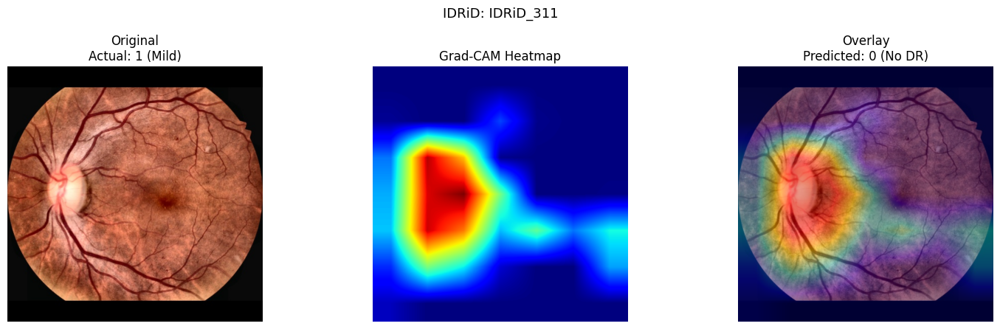

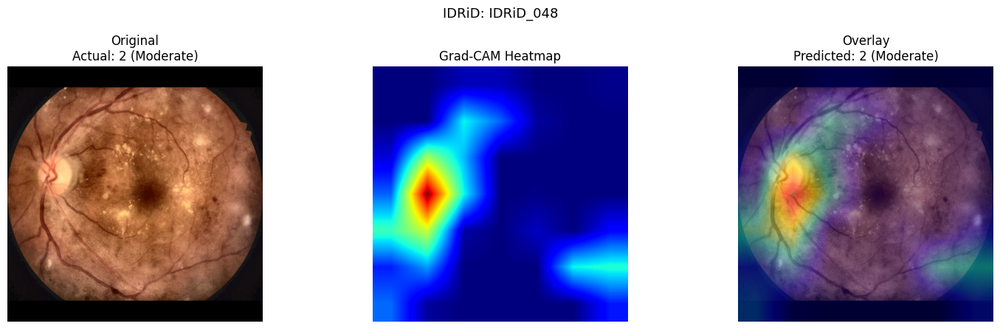

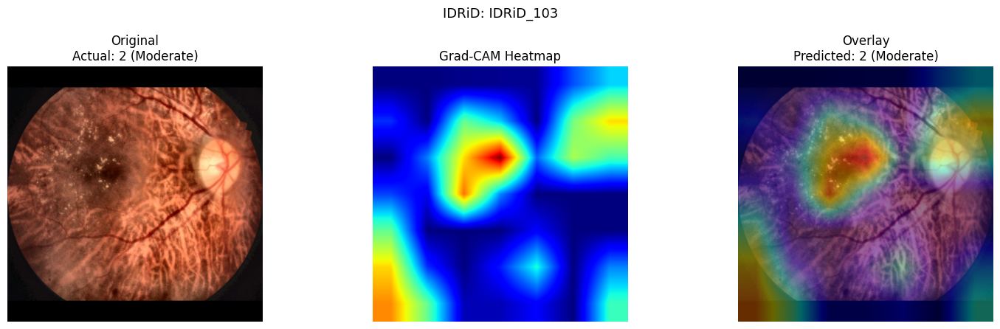

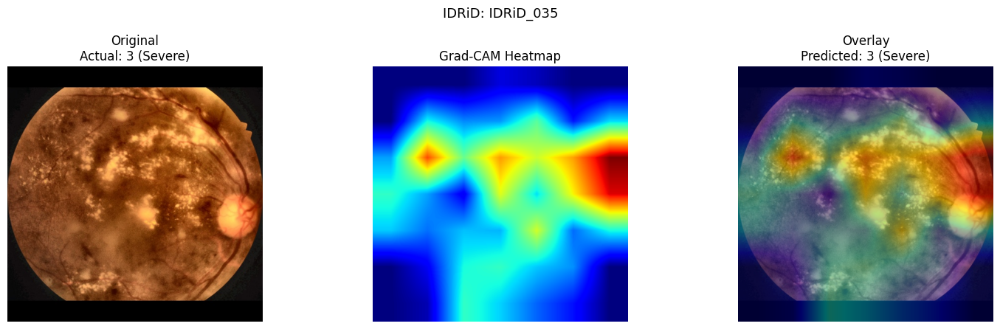

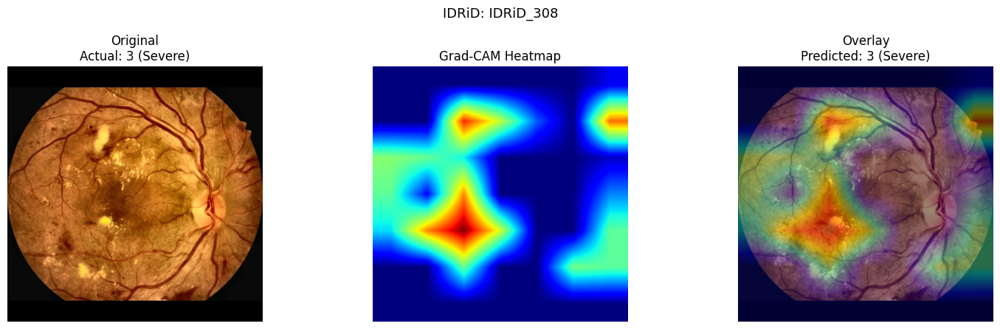

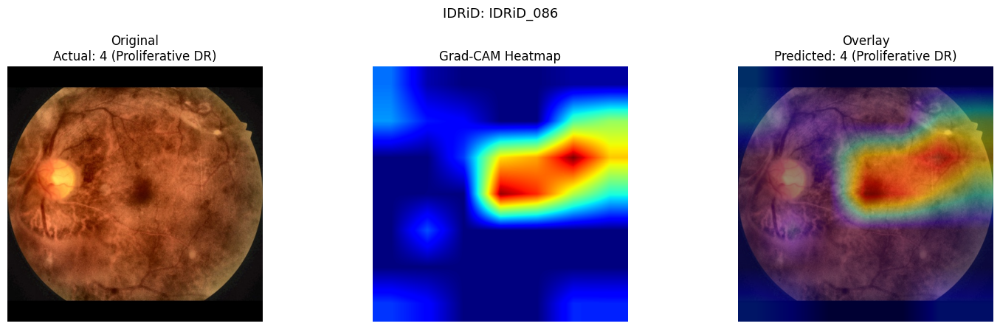

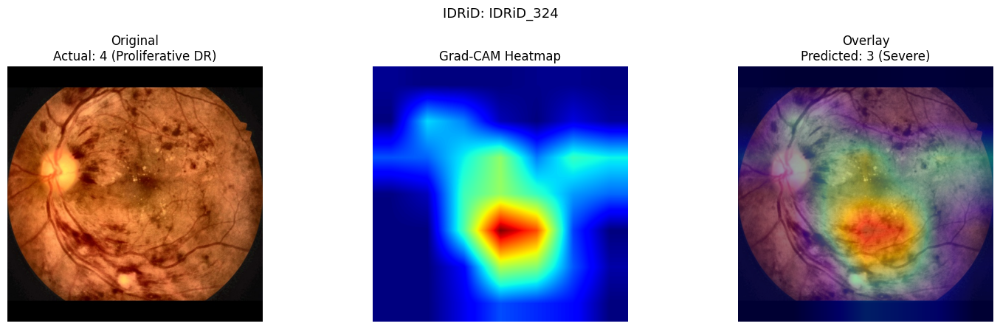

IDRiD images visualized: 10


,image_id,actual_grade,predicted_grade,actual_binary,predicted_binary,grade_correct,binary_correct,predicted_class_score
0,IDRiD_211,0,0,Non-Referable,Non-Referable,True,True,0.898650
1,IDRiD_228,0,0,Non-Referable,Non-Referable,True,True,0.828320
2,IDRiD_105,1,1,Non-Referable,Non-Referable,True,True,0.570707
3,IDRiD_311,1,0,Non-Referable,Non-Referable,False,True,0.745200
4,IDRiD_048,2,2,Referable,Referable,True,True,0.447907
5,IDRiD_103,2,2,Referable,Referable,True,True,0.572063
6,IDRiD_035,3,3,Referable,Referable,True,True,0.925988
7,IDRiD_308,3,3,Referable,Referable,True,True,0.391371
8,IDRiD_086,4,4,Referable,Referable,True,True,0.385542
9,IDRiD_324,4,3,Referable,Referable,False,True,0.898052


In [14]:
idrid_gradcam_results = []

for _, row in idrid_selected_df.iterrows():
    image_path = Path(row["image_path"])
    actual_grade = int(row["diagnosis"])

    image_bgr = cv2.imread(str(image_path))
    if image_bgr is None:
        print("Skipping unreadable image:", image_path.name)
        continue

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    # Prepare model input
    image_resized = cv2.resize(image_rgb, IMAGE_SIZE)
    img_array = np.expand_dims(
        image_resized.astype(np.float32), axis=0
    )

    # Grad-CAM and prediction
    heatmap, predicted_grade, probabilities = make_gradcam_heatmap(
        img_array=img_array,
        model=model,
        backbone=backbone
    )

    heatmap_resized = cv2.resize(
        heatmap, (image_rgb.shape[1], image_rgb.shape[0])
    )

    heatmap_color = cv2.applyColorMap(
        np.uint8(255 * heatmap_resized),
        cv2.COLORMAP_JET
    )
    heatmap_color = cv2.cvtColor(
        heatmap_color, cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        image_rgb, 0.60, heatmap_color, 0.40, 0
    )

    actual_binary = (
        "Non-Referable" if actual_grade <= 1 else "Referable"
    )
    predicted_binary = (
        "Non-Referable" if predicted_grade <= 1 else "Referable"
    )

    idrid_gradcam_results.append({
        "image_id": row["id_code"],
        "actual_grade": actual_grade,
        "predicted_grade": predicted_grade,
        "actual_binary": actual_binary,
        "predicted_binary": predicted_binary,
        "grade_correct": actual_grade == predicted_grade,
        "binary_correct": actual_binary == predicted_binary,
        "predicted_class_score": float(
            probabilities[predicted_grade]
        )
    })

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    axes[0].imshow(image_rgb)
    axes[0].set_title(
        f"Original\nActual: {actual_grade} "
        f"({CLASS_NAMES[actual_grade]})"
    )

    axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM Heatmap")

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"Overlay\nPredicted: {predicted_grade} "
        f"({CLASS_NAMES[predicted_grade]})"
    )

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"IDRiD: {row['id_code']}", fontsize=13)
    plt.tight_layout()
    plt.show()

idrid_gradcam_results_df = pd.DataFrame(idrid_gradcam_results)

print("IDRiD images visualized:", len(idrid_gradcam_results_df))
display(idrid_gradcam_results_df)

In [15]:
from pathlib import Path
import pandas as pd
import cv2
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_ROOT = Path("/kaggle/working/resnet50_gradcam")
APTOS_OUT = OUTPUT_ROOT / "APTOS"
IDRID_OUT = OUTPUT_ROOT / "IDRiD"

for folder in [APTOS_OUT, IDRID_OUT]:
    (folder / "originals").mkdir(parents=True, exist_ok=True)
    (folder / "heatmaps").mkdir(parents=True, exist_ok=True)
    (folder / "overlays").mkdir(parents=True, exist_ok=True)

def save_gradcam_images(selected_df, output_df, output_dir, dataset_name):
    saved_rows = []

    for _, row in selected_df.iterrows():
        image_id = str(row["id_code"])
        image_path = Path(row["image_path"])

        image_bgr = cv2.imread(str(image_path))
        if image_bgr is None:
            print(f"Skipping unreadable image: {image_path}")
            continue

        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        resized = cv2.resize(image_rgb, IMAGE_SIZE)
        img_array = np.expand_dims(resized.astype(np.float32), axis=0)

        heatmap, predicted_grade, probabilities = make_gradcam_heatmap(
            img_array=img_array,
            model=model,
            backbone=backbone
        )

        heatmap_resized = cv2.resize(
            heatmap, (image_rgb.shape[1], image_rgb.shape[0])
        )
        heatmap_color = cv2.applyColorMap(
            np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET
        )
        heatmap_color = cv2.cvtColor(
            heatmap_color, cv2.COLOR_BGR2RGB
        )

        overlay = cv2.addWeighted(
            image_rgb, 0.60, heatmap_color, 0.40, 0
        )

        # Save images as RGB-correct PNG files
        cv2.imwrite(
            str(output_dir / "originals" / f"{image_id}.png"),
            cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
        )
        cv2.imwrite(
            str(output_dir / "heatmaps" / f"{image_id}_heatmap.png"),
            cv2.cvtColor(heatmap_color, cv2.COLOR_RGB2BGR)
        )
        cv2.imwrite(
            str(output_dir / "overlays" / f"{image_id}_overlay.png"),
            cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
        )

        saved_rows.append({
            "image_id": image_id,
            "actual_grade": int(row["diagnosis"]),
            "predicted_grade": predicted_grade,
            "actual_binary": (
                "Non-Referable" if int(row["diagnosis"]) <= 1
                else "Referable"
            ),
            "predicted_binary": (
                "Non-Referable" if predicted_grade <= 1
                else "Referable"
            ),
            "grade_correct": int(row["diagnosis"]) == predicted_grade,
            "binary_correct": (
                (int(row["diagnosis"]) <= 1) == (predicted_grade <= 1)
            ),
            "predicted_class_score": float(probabilities[predicted_grade])
        })

    saved_df = pd.DataFrame(saved_rows)
    saved_df.to_csv(output_dir / f"{dataset_name.lower()}_gradcam_results.csv",
                    index=False)

    print(f"{dataset_name}: saved {len(saved_df)} images")
    return saved_df


# Save APTOS examples
aptos_saved_df = save_gradcam_images(
    selected_df, results_df, APTOS_OUT, "APTOS"
)

# Save IDRiD examples
idrid_saved_df = save_gradcam_images(
    idrid_selected_df, idrid_gradcam_results_df, IDRID_OUT, "IDRiD"
)

print("\nAll Grad-CAM outputs saved to:", OUTPUT_ROOT)

APTOS: saved 10 images
IDRiD: saved 10 images

All Grad-CAM outputs saved to: /kaggle/working/resnet50_gradcam
